# Analysis Pipeline

In this notebook we analyse the quality of the ScArches mapping using the *MappingAccessment* package. 

In [1]:
# import os
# os.chdir('../')
import warnings

warnings.simplefilter(action="ignore", category=FutureWarning)
warnings.simplefilter(action="ignore", category=UserWarning)

In [2]:
import scanpy as sc
import anndata
import matplotlib.pyplot as plt
import numpy as np
import scipy

import pandas as pd
import datetime
import statsmodels.stats.multitest as mtc
import json
import timeit
from MappingAssessment import MapAnalyzer, Plotter


In [3]:
workspace = "C:\\Users\\49176\\PycharmProjects\\Bachelor\\HLCA"

In [5]:
#set parameters here
dataset = "Kaminski_2020"
ident = "Kaminski_2020"
query_color = "Blue"
condition = "IPF"
exclude = ["COPD"]

In [6]:
adata= sc.read(f'{workspace}\\Adatas\\HLCA_full_v1.h5ad')

In [12]:
adata = adata[(adata.obs.core_or_extension=="core")|((adata.obs.dataset==dataset))]

### Preprocessing

Set clean cell labels on all levels and one label-column for transfer from curated metadata, assumed to be done in the package 

In [190]:
# In case that no umap based on the embedding is calculated, recalculate the UMAP
# sc.pp.neighbors(adata, n_neighbors=50, n_pcs=30)
# sc.tl.umap(adata)

Initialize *AdataHandler* object. The *AdataHandler* makes sure all columns are named a standarized way. It also is able to perform a label transfer to the query.

In [191]:
import imp

imp.reload(MapAnalyzer)

<module 'MappingAssessment.MapAnalyzer' from 'C:\\Users\\49176\\PycharmProjects\\Bachelor\\HLCA\\Mapping_package\\MappingAssessment\\MapAnalyzer.py'>

In [192]:
adata_handler = MapAnalyzer.AdataHandler(
    adata,
    workspace=f"{workspace}\\MapAnalyzer_Results_3.0\\",
    ident=ident+"\\",  # folder that indentifies this workpartition
    log=True,  # create a logfile
)

Logger directory already exists


In [193]:
# Plotter object for the plots
plotter = Plotter.MapPlot(workspace=f"{adata_handler.workspace}/{ident}")

In [ ]:
adata_handler.standarize_columns(
    condition_name=condition,  # condition name we want to distinguish
    query_dataset=dataset,  # query datasets
    cell_type_col=None,  # column name denoting celltype, none if no unified column
    dataset_col="dataset",  # column name denoting dataset
    sample_col="sample",  # column name danoting sample
    condition_col="lung_condition",  # column name denoting condition (abovementioned)
    subject_col="donor_id",  # column name denoting patients, subjects or donors
    disease_exclude=exclude,  # diseases to exclude from analysis
)

Set appropriate levels for the cell type annoation

In [ ]:
adata_handler.set_cell_type_levels(1,['ann_level_1', 'ann_level_2', 'ann_level_3', 'ann_level_4', 'ann_level_5'],"ann_finest_level","nan")

In [20]:
adata= adata_handler.get_adata()

Transfer celltype labels from reference data to query cells

In [22]:
adata_handler.transfer_labels(transfer_columns=["cell_label"],pickle=False)

2023-05-15 19:13:25.068736	Transferring labels...
2023-05-15 19:13:26.867051	Train KNNModel
Weighted KNN with n_neighbors = 50 ... 2023-05-15 19:13:27.556037	Transfer Labels
2023-05-15 19:13:27.556037	transferring cell_label
finished!


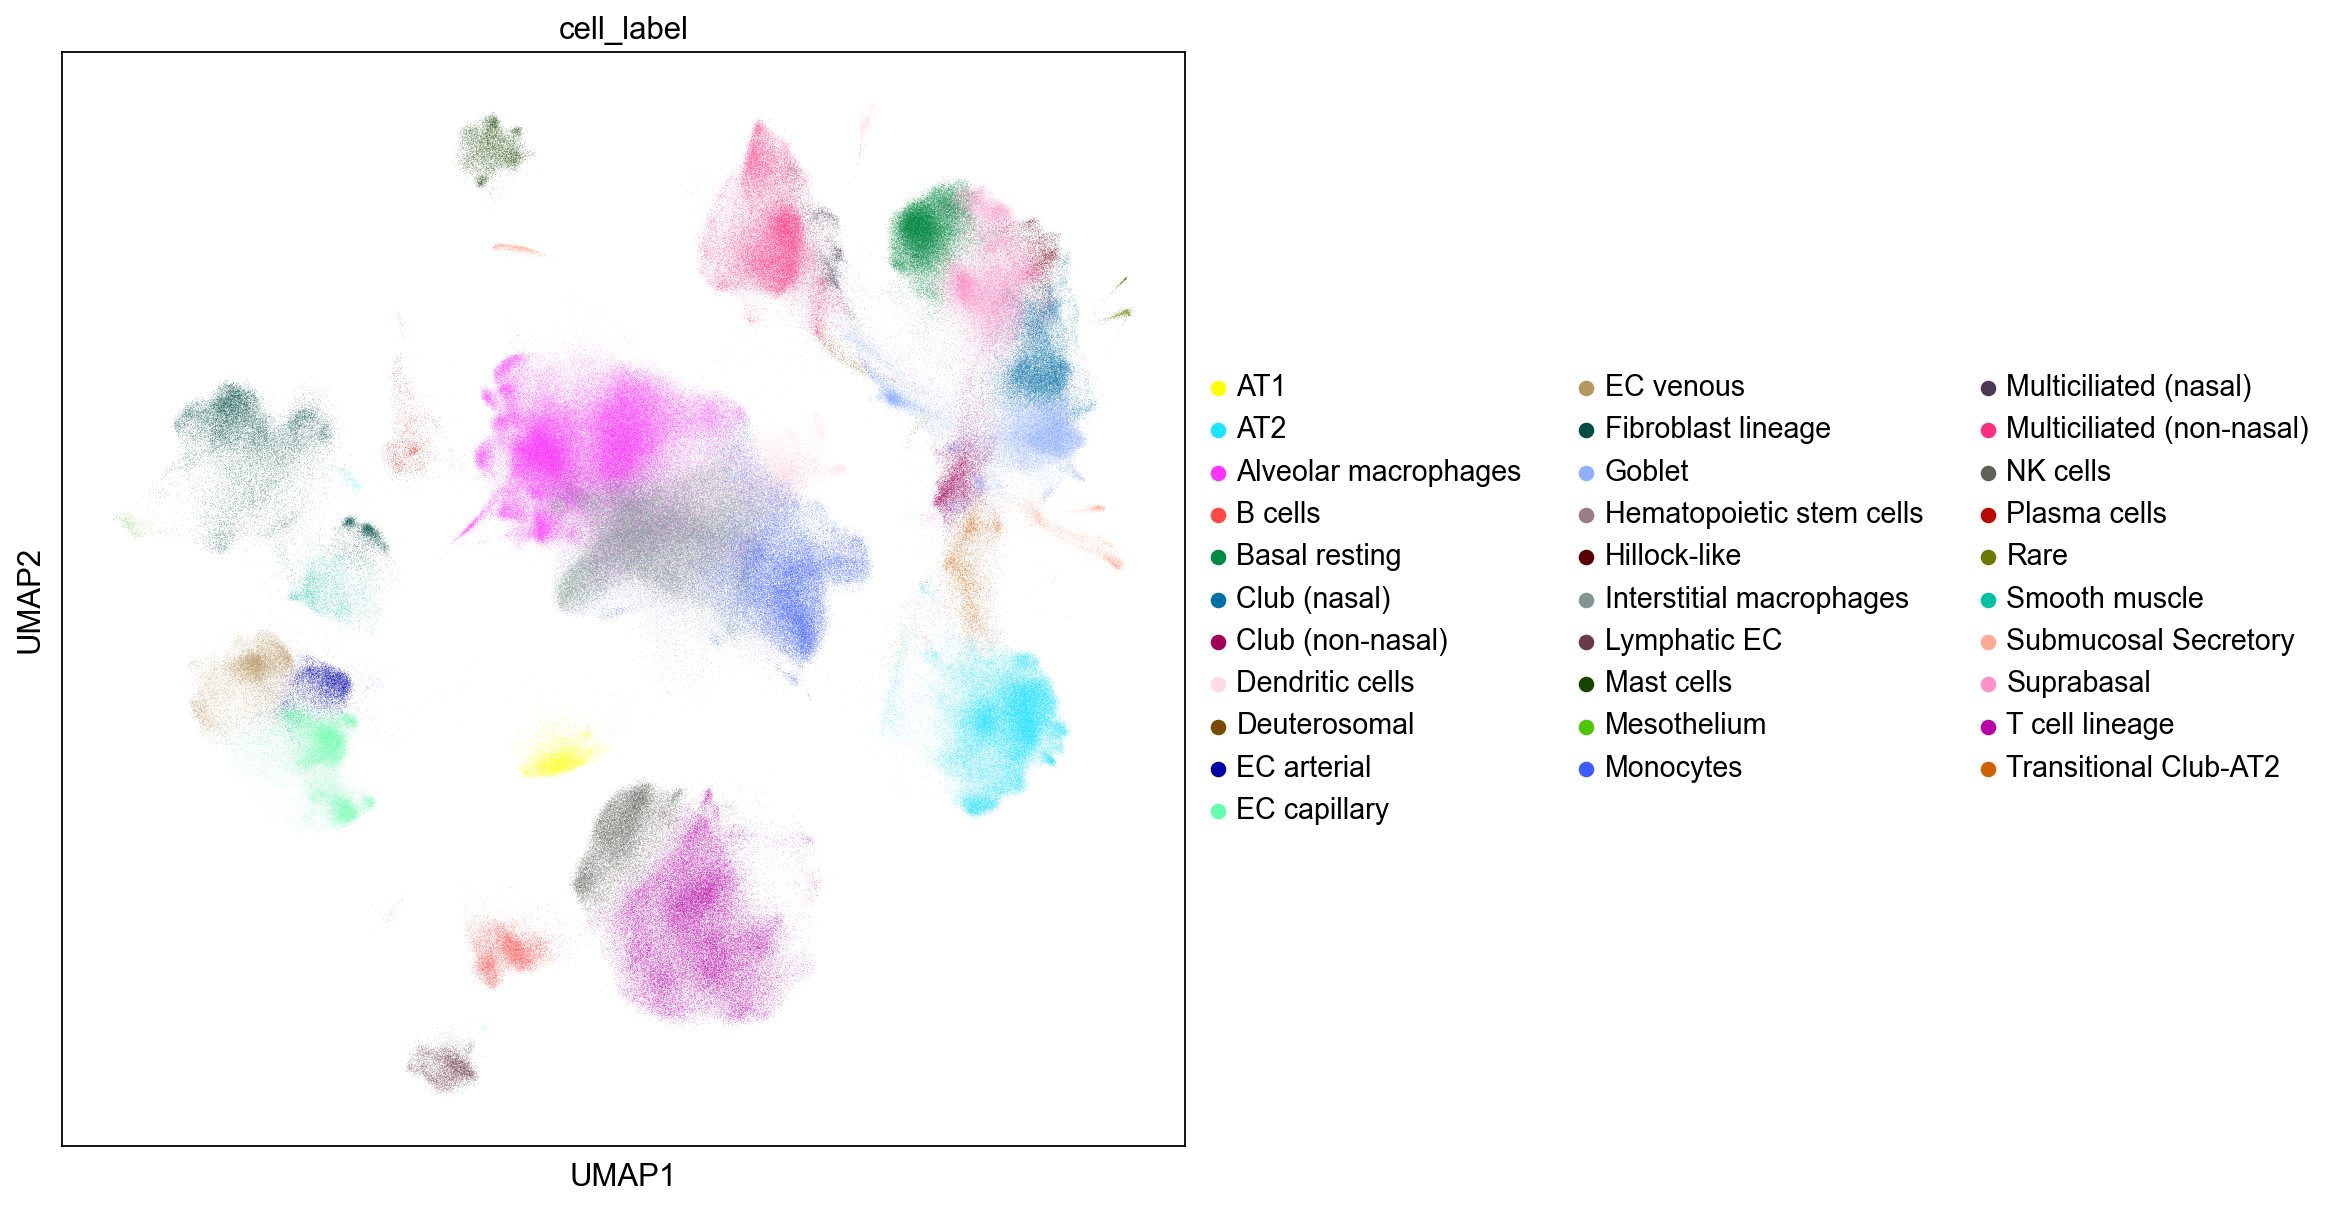

In [23]:
sc.pl.umap(adata,color="cell_label")

In [33]:
adata.obs[["query_or_reference","cell_label"]]

,query_or_reference,cell_label
CGATGTAAGTTACGGG_SC10,reference,Alveolar macrophages
ATTCTACCAAGGTTCT_HD68,reference,EC capillary
P1_2_TGCTGCTAGCTCCTCT,reference,Alveolar macrophages
CTGATAGTCTTAGAGC_F01367,reference,EC arterial
D344_Brus_Dis1_CATTCGCGTGCCTGCA-1-14,reference,Club (non-nasal)
...,...,...
P3_4_TAAACCGGTGTCCTCT,reference,Fibroblast lineage
P3_4_GCTTGAACACGACGAA,reference,Fibroblast lineage
TCAGGATCAAGACGTG_F02526,reference,Multiciliated (non-nasal)
022C-b_GGATGTTTCCAAGTAC_adams,query,Alveolar macrophages


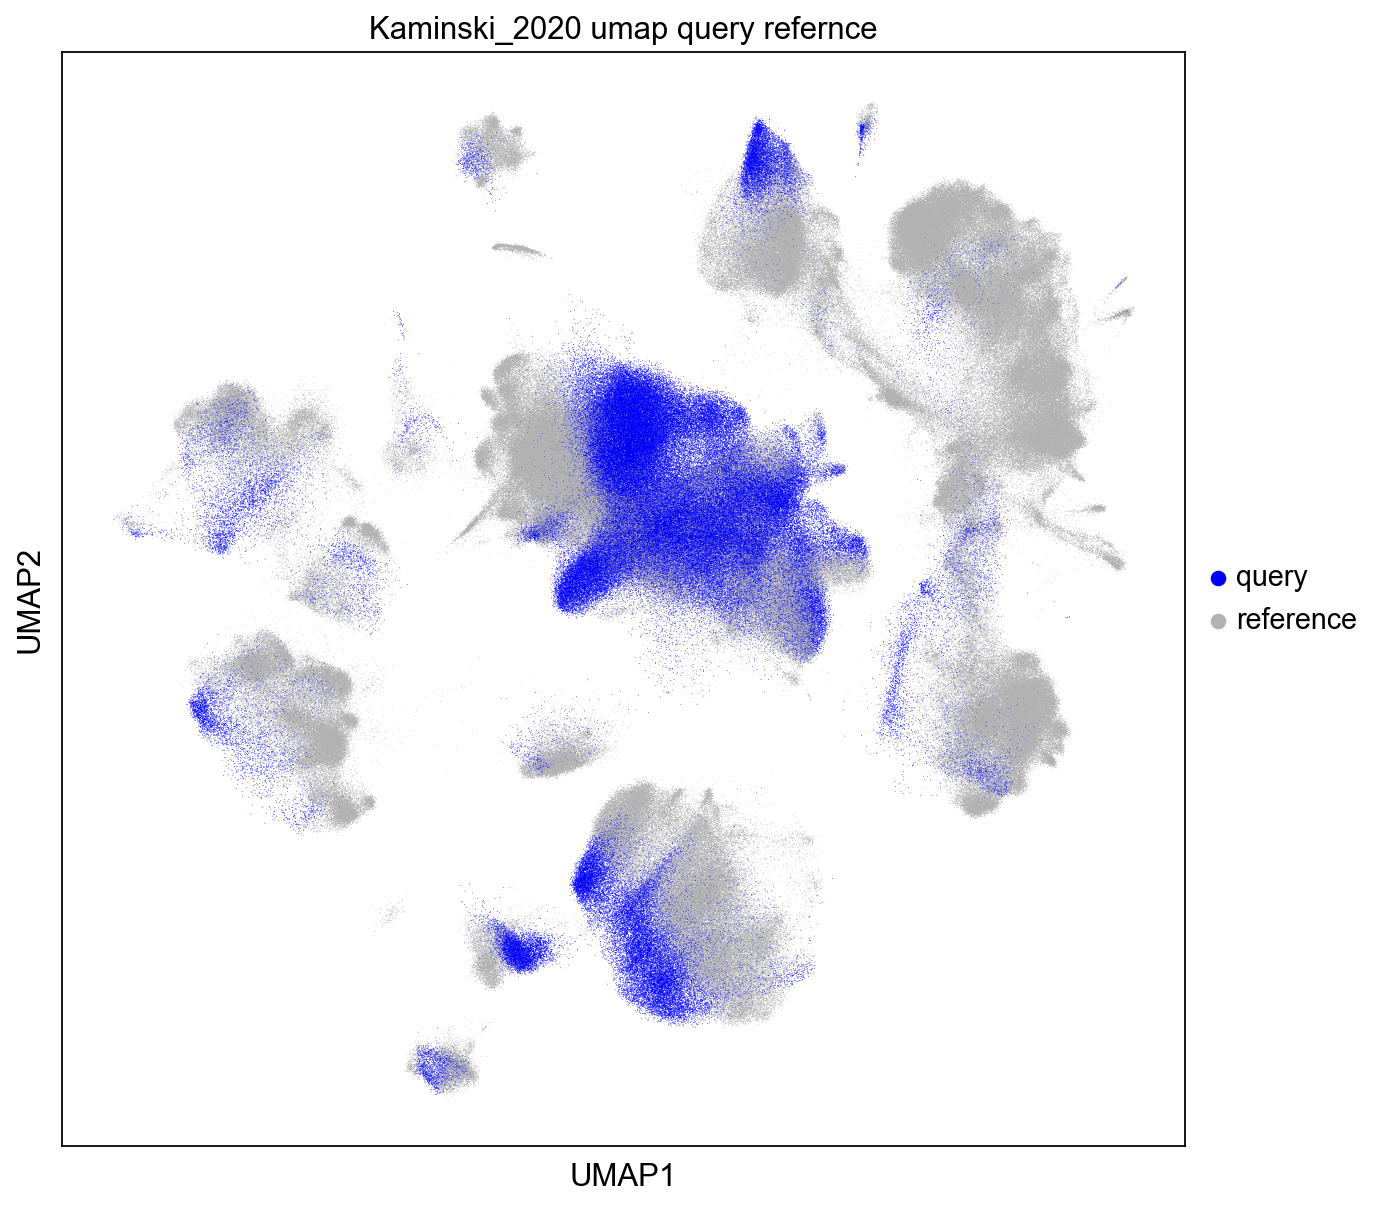

In [31]:
plotter.umap_query_reference(
    adata, color_query=query_color, title_stub=ident, save=False
)

In [208]:
import imp

imp.reload(MapAnalyzer)

<module 'MappingAssessment.MapAnalyzer' from 'C:\\Users\\49176\\PycharmProjects\\Bachelor\\HLCA\\Mapping_package\\MappingAssessment\\MapAnalyzer.py'>

### Main Pipeline

Initialize the *MappingScoring* object. Pass the *AdataHandler* so that adata and workspace information is passed on.

In [209]:
scorer = MapAnalyzer.MappingScoring(adata_handler)

Logger directory already exists
2023-05-16 00:33:50.034507	Checking columns...


In [210]:
adata = scorer.get_adata()

#### Calculate or pass query mixing scores

In [211]:
'''scorer.calculate_mixing_scores(
    n_neighbors=15,
    min_subjects=40,
    samples=None,
    reinitialize=True,
    embedding="X",
    verbose=True,
    overwrite=True,
    save=True,
)'''

'scorer.calculate_mixing_scores(\n    n_neighbors=15,\n    min_subjects=40,\n    samples=None,\n    reinitialize=True,\n    embedding="X",\n    verbose=True,\n    overwrite=True,\n    save=True,\n)'

In [212]:
scorer.add_scores(
    f"{scorer.workspace}\\{ident}\\scores.csv",
)

**Baseline calculation:**  
To compare our mapping to a upper bound, we calculate the scores for the integrated reference. For that we set one sample to query, while the other samples are set to reference (excluding the real query). By that we achieve a baseline for each celltype of how well different samples are integrated. We then can compare out mapping scores to the baseline to see, wether the mapping is of comparable quality to the integration. 

In [225]:
scorer.calculate_baseline(save=True,verbose=True)

2023-05-16 00:54:36.829053	Analyzing AT1
2023-05-16 00:54:36.948063	skipping AT1 with 35 subjects
2023-05-16 00:54:36.948063	Analyzing AT2
2023-05-16 00:54:37.440874	       Analysing F02522
2023-05-16 00:54:40.923018	       skipping D367_Brus_Dis1 with 0 cells
2023-05-16 00:54:40.936005	       skipping SC172 with 0 cells
2023-05-16 00:54:40.949017	       skipping SC181 with 0 cells
2023-05-16 00:54:40.962023	       Analysing distal 1a
2023-05-16 00:54:45.340034	       skipping SC14 with 3 cells
2023-05-16 00:54:45.354035	       Analysing SC56
2023-05-16 00:54:50.040901	       Analysing 356C_0h
2023-05-16 00:54:54.527074	       skipping SC89 with 0 cells
2023-05-16 00:54:54.543092	       Analysing SC24
2023-05-16 00:54:57.638851	       skipping GRO-09_nasal_brush with 0 cells
2023-05-16 00:54:57.651871	       skipping T120 with 2 cells
2023-05-16 00:54:57.662881	       skipping T165 with 0 cells
2023-05-16 00:54:57.677817	       Analysing 7239217
2023-05-16 00:55:02.197945	Analyzing Alv

2023-05-16 00:56:59.484896	       Analysing D367_Brus_Dis1
2023-05-16 00:57:00.831654	       skipping SC172 with 13 cells
2023-05-16 00:57:00.846648	       Analysing SC181
2023-05-16 00:57:02.197180	       Analysing distal 1a
2023-05-16 00:57:02.996686	       skipping SC14 with 0 cells
2023-05-16 00:57:03.011657	       Analysing SC56
2023-05-16 00:57:04.264698	       skipping 356C_0h with 11 cells
2023-05-16 00:57:04.277698	       skipping SC89 with 1 cells
2023-05-16 00:57:04.290704	       skipping SC24 with 7 cells
2023-05-16 00:57:04.302678	       skipping GRO-09_nasal_brush with 0 cells
2023-05-16 00:57:04.314675	       skipping T120 with 0 cells
2023-05-16 00:57:04.325686	       skipping T165 with 0 cells
2023-05-16 00:57:04.337676	       skipping 7239217 with 0 cells
2023-05-16 00:57:04.337676	Analyzing Mesothelium
2023-05-16 00:57:04.381691	skipping Mesothelium with 5 subjects
2023-05-16 00:57:04.381691	Analyzing Monocytes
2023-05-16 00:57:04.594512	       Analysing F02522
2023-

2023-05-16 00:59:55.373240	       skipping GRO-03_nasal_brush with 2 cells
2023-05-16 00:59:55.387278	       skipping T89 with 0 cells
2023-05-16 00:59:55.401239	       skipping T167 with 0 cells
2023-05-16 00:59:55.416239	       Analysing 7119453
2023-05-16 01:00:02.633456	Analyzing B cells
2023-05-16 01:00:02.947890	skipping B cells with 36 subjects
2023-05-16 01:00:02.948889	Analyzing Basal resting
2023-05-16 01:00:04.190922	skipping Basal resting with 38 subjects
2023-05-16 01:00:04.192923	Analyzing Club (nasal)
2023-05-16 01:00:04.946494	skipping Club (nasal) with 29 subjects
2023-05-16 01:00:04.947496	Analyzing Club (non-nasal)
2023-05-16 01:00:05.172866	skipping Club (non-nasal) with 32 subjects
2023-05-16 01:00:05.172866	Analyzing Dendritic cells
2023-05-16 01:00:05.452022	       Analysing VUHD66
2023-05-16 01:00:06.587604	       Analysing D372_Biop_Int2
2023-05-16 01:00:07.818401	       skipping SC173 with 14 cells
2023-05-16 01:00:07.834421	       Analysing SC184
2023-05-16 0

2023-05-16 01:01:31.278608	       Analysing VUHD66
2023-05-16 01:01:33.674127	       Analysing D372_Biop_Int2
2023-05-16 01:01:35.822266	       Analysing SC173
2023-05-16 01:01:38.682140	       Analysing SC184
2023-05-16 01:01:41.418495	       Analysing distal 2
2023-05-16 01:01:44.201305	       Analysing SC31D
2023-05-16 01:01:47.094518	       Analysing SC156
2023-05-16 01:01:50.379963	       skipping 356C_24h with 9 cells
2023-05-16 01:01:50.393962	       Analysing SC143
2023-05-16 01:01:53.201258	       Analysing SC27
2023-05-16 01:01:56.451294	       Analysing GRO-03_nasal_brush
2023-05-16 01:01:58.768453	       Analysing T89
2023-05-16 01:02:01.804038	       Analysing T167
2023-05-16 01:02:05.354363	       skipping 7119453 with 0 cells
2023-05-16 01:02:05.354363	Analyzing NK cells
2023-05-16 01:02:05.543035	       Analysing VUHD66
2023-05-16 01:02:06.716061	       skipping D372_Biop_Int2 with 2 cells
2023-05-16 01:02:06.736020	       skipping SC173 with 4 cells
2023-05-16 01:02:06

SystemError: CPUDispatcher(<function nn_descent at 0x0000024B72761CF0>) returned a result with an exception set

In [214]:
scorer.add_baseline(
    f"{scorer.workspace}\\baseline.csv",
    f"{workspace}\\MapAnalyzer_Results_3.0\\celltypes.txt",
)

2023-05-16 00:33:54.282161	Baseline consists of following cell types:

2023-05-16 00:33:54.282161	AT2


2023-05-16 00:33:54.283203	Alveolar macrophages


2023-05-16 00:33:54.283203	Dendritic cells


2023-05-16 00:33:54.283203	EC arterial


2023-05-16 00:33:54.283203	EC venous


2023-05-16 00:33:54.283203	Fibroblast lineage


2023-05-16 00:33:54.283203	Goblet


2023-05-16 00:33:54.283203	Interstitial macrophages


2023-05-16 00:33:54.283203	Mast cells


2023-05-16 00:33:54.283203	Monocytes


2023-05-16 00:33:54.283203	Multiciliated (non-nasal)


2023-05-16 00:33:54.283203	NK cells


2023-05-16 00:33:54.283203	Suprabasal


2023-05-16 00:33:54.283203	T cell lineage


2023-05-16 00:33:54.283203	Transitional Club-AT2




add correction model for score correction for sample size:

In [215]:
scorer.add_transformation(f"{workspace}\\MapAnalyzer_Results_3.0\\transformation.csv")

In [226]:
scorer.calculate_transformation()

### Analyzing the Mapping with MapAnalyzer

In [216]:
adata = scorer.get_adata()

In [217]:
scorer.analyze_mapping()

2023-05-16 00:34:00.547606	Correcting the for sample size...
2023-05-16 00:34:13.687472	001C: ['AT2', 'Alveolar macrophages', 'Dendritic cells', 'Fibroblast lineage', 'Interstitial macrophages', 'Monocytes', 'NK cells', 'T cell lineage']
2023-05-16 00:34:14.653098	Correcting the for sample size...
2023-05-16 00:34:28.094079	002C: ['Alveolar macrophages', 'Interstitial macrophages', 'Monocytes', 'Multiciliated (non-nasal)', 'T cell lineage']
2023-05-16 00:34:29.059482	Correcting the for sample size...
2023-05-16 00:34:42.419345	003C: ['AT2', 'Alveolar macrophages', 'Dendritic cells', 'Fibroblast lineage', 'Interstitial macrophages', 'Monocytes', 'Multiciliated (non-nasal)', 'NK cells', 'T cell lineage']
2023-05-16 00:34:43.359771	Correcting the for sample size...
2023-05-16 00:34:56.934676	010I: ['AT2', 'Alveolar macrophages', 'Dendritic cells', 'EC venous', 'Fibroblast lineage', 'Goblet', 'Interstitial macrophages', 'Mast cells', 'Monocytes', 'Multiciliated (non-nasal)', 'NK cells', 'T

2023-05-16 00:41:46.944393	137C: ['Alveolar macrophages', 'Dendritic cells', 'Fibroblast lineage', 'Interstitial macrophages', 'Monocytes', 'NK cells', 'T cell lineage']
2023-05-16 00:41:47.872905	Correcting the for sample size...
2023-05-16 00:42:01.084979	137C-a: ['AT2', 'Alveolar macrophages', 'Dendritic cells', 'EC venous', 'Fibroblast lineage', 'Interstitial macrophages', 'Monocytes', 'Multiciliated (non-nasal)', 'NK cells', 'T cell lineage']
2023-05-16 00:42:02.043606	Correcting the for sample size...
2023-05-16 00:42:15.289772	137C-b: ['AT2', 'Alveolar macrophages', 'Dendritic cells', 'EC arterial', 'EC venous', 'Fibroblast lineage', 'Interstitial macrophages', 'Monocytes', 'Multiciliated (non-nasal)', 'NK cells', 'T cell lineage']
2023-05-16 00:42:16.227550	Correcting the for sample size...
2023-05-16 00:42:29.602942	138I: ['Alveolar macrophages', 'Dendritic cells', 'Fibroblast lineage', 'Interstitial macrophages', 'Monocytes']
2023-05-16 00:42:30.559292	Correcting the for samp

2023-05-16 00:48:28.483217	Correcting the for sample size...
2023-05-16 00:48:41.568596	225I-a: ['Alveolar macrophages', 'Dendritic cells', 'EC venous', 'Fibroblast lineage', 'Interstitial macrophages', 'Mast cells', 'Monocytes', 'Multiciliated (non-nasal)', 'NK cells', 'T cell lineage']
2023-05-16 00:48:42.494446	Correcting the for sample size...
2023-05-16 00:48:55.770456	225I-b: ['AT2', 'Alveolar macrophages', 'Dendritic cells', 'EC arterial', 'EC venous', 'Fibroblast lineage', 'Interstitial macrophages', 'Mast cells', 'Monocytes', 'Multiciliated (non-nasal)', 'NK cells', 'T cell lineage']
2023-05-16 00:48:56.687002	Correcting the for sample size...
2023-05-16 00:49:09.637695	226C-a: ['AT2', 'Alveolar macrophages', 'Dendritic cells', 'Interstitial macrophages', 'Monocytes', 'Multiciliated (non-nasal)', 'NK cells', 'T cell lineage']
2023-05-16 00:49:10.564823	Correcting the for sample size...
2023-05-16 00:49:23.562422	226C-b: ['AT2', 'Alveolar macrophages', 'Dendritic cells', 'Fibro

In [227]:
scorer.report

,cell_label,sample,mean,health_status,excluded,label
0,AT2,001C,0.473060,healthy,False,"(healthy accepted,)"
1,Alveolar macrophages,001C,0.340329,healthy,False,"(healthy accepted,)"
2,Dendritic cells,001C,0.761578,healthy,False,"(healthy accepted,)"
3,Fibroblast lineage,001C,0.866543,healthy,False,"(healthy accepted,)"
4,Interstitial macrophages,001C,0.658848,healthy,False,"(healthy accepted,)"
...,...,...,...,...,...,...
757,Fibroblast lineage,92C,0.679207,healthy,False,"(healthy accepted,)"
758,Interstitial macrophages,92C,0.141967,healthy,True,"(healthy rejected,)"
759,Monocytes,92C,0.234821,healthy,False,"(healthy accepted,)"
760,NK cells,92C,0.186029,healthy,True,"(healthy rejected,)"


In [228]:
scorer.sample_report

health_status excluded        fraction accepted
               first      sum count                   
sample                                                
001C         healthy        0     8  0.000000     True
002C         healthy        0     5  0.000000     True
003C         healthy        1     9  0.111111     True
010I         disease        3    13  0.230769     True
021I         disease        3    12  0.250000    False
...              ...      ...   ...       ...      ...
484C         healthy        3     6  0.500000    False
49I-a        disease        2     9  0.222222     True
49I-b        disease        1     9  0.111111     True
59I          disease        1     9  0.111111     True
92C          healthy        2     6  0.333333    False

[83 rows x 5 columns]

In [229]:
scorer.report.to_csv(
    f"{workspace}\\MapAnalyzer_Results_3.0\\{ident}\\report.csv"
)

### Plotting the outcomes

In [235]:
report = scorer.report.rename(columns={"accepted"})

In [231]:
adata = adata[adata.obs.cell_label.isin(scorer.cell_types)]

In [232]:
adata

View of AnnData object with n_obs × n_vars = 594651 × 30
    obs: 'suspension_type', 'subject_ID', 'is_primary_data', 'assay_ontology_term_id', 'cell_type_ontology_term_id', 'development_stage_ontology_term_id', 'disease_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'tissue_ontology_term_id', 'organism_ontology_term_id', 'sex_ontology_term_id', "3'_or_5'", 'BMI', 'age_or_mean_of_age_range', 'age_range', 'anatomical_region_ccf_score', 'ann_coarse_for_GWAS_and_modeling', 'ann_finest_level', 'ann_level_1', 'ann_level_2', 'ann_level_3', 'ann_level_4', 'ann_level_5', 'cause_of_death', 'core_or_extension', 'dataset', 'fresh_or_frozen', 'log10_total_counts', 'lung_condition', 'mixed_ancestry', 'original_ann_level_1', 'original_ann_level_2', 'original_ann_level_3', 'original_ann_level_4', 'original_ann_level_5', 'original_ann_nonharmonized', 'reannotation_type', 'sample', 'scanvi_label', 'sequencing_platform', 'smoking_status', 'study', 'subject_type', 'tissue_coarse_unharmoni

C:\Users\49176\anaconda3\envs\metricselection\lib\site-packages\pandas\core\arraylike.py:397: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


No failed filtering


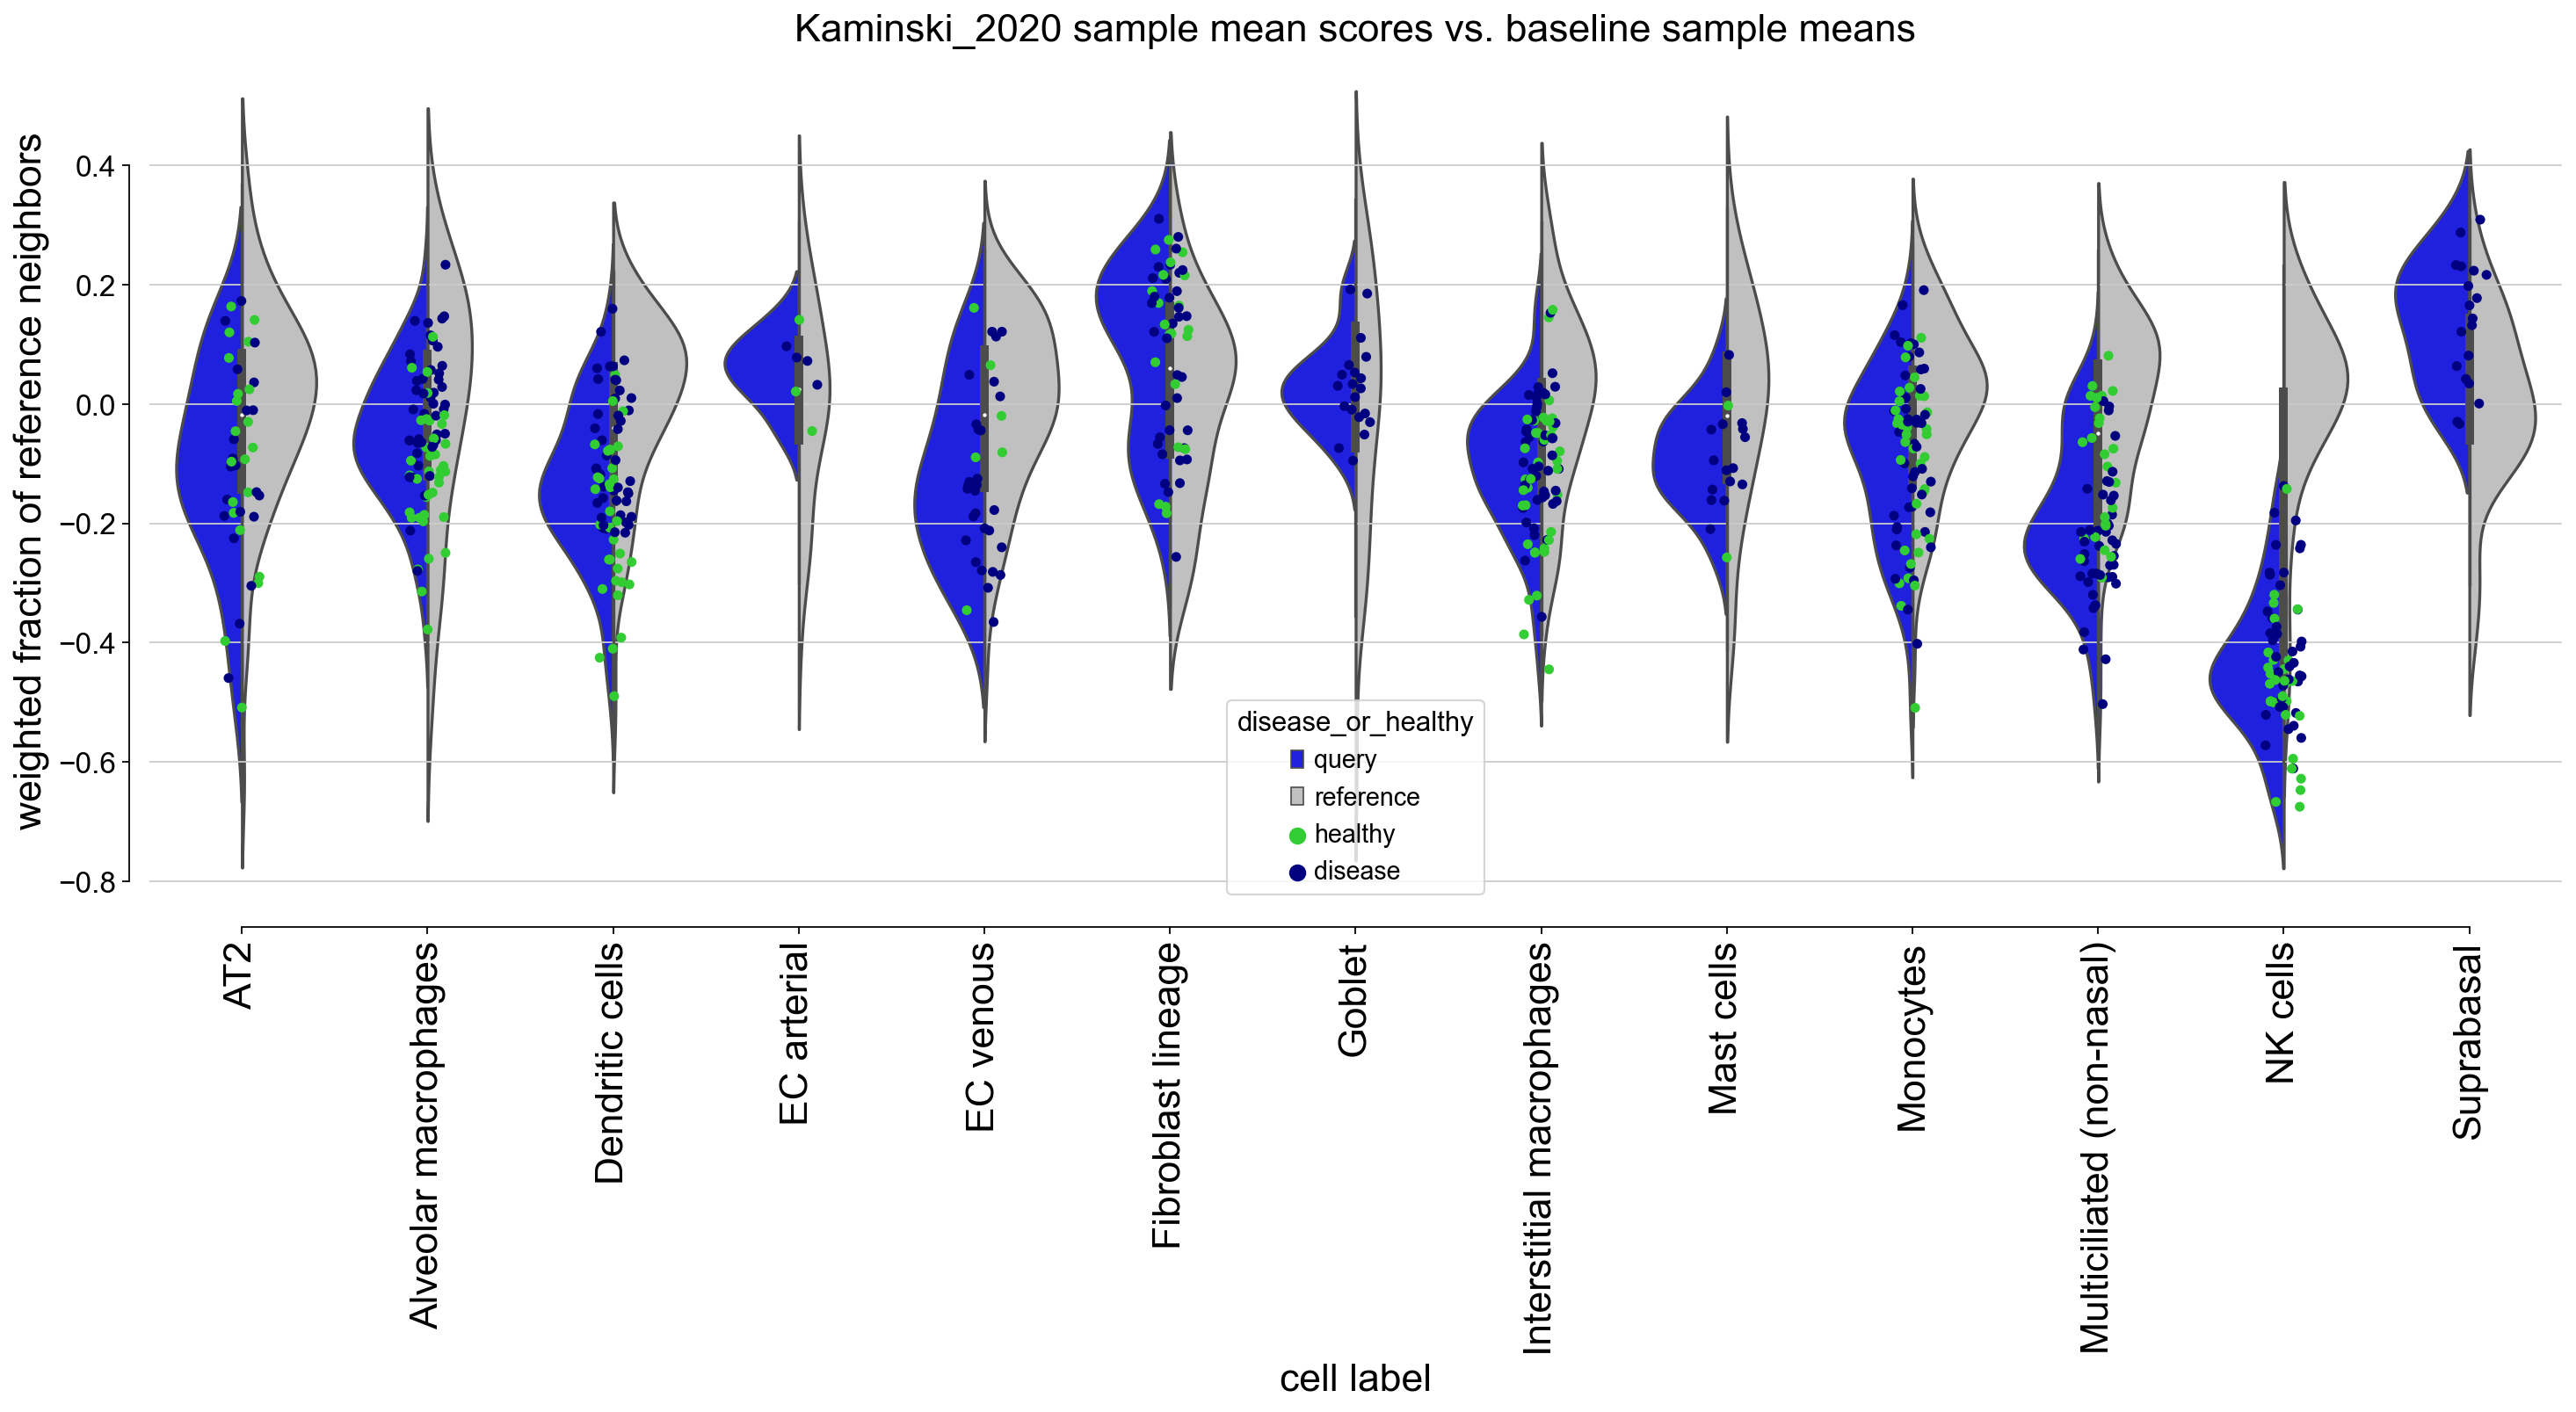

In [237]:
plotter.plot_baseline_comparison(
    adata,
    query_color,
    ident,
    disease=True,
    save=True,
    violin=True,
    #sample_filter=report,
    transform=f"{workspace}\\MapAnalyzer_Results_3.0\\transformation.csv",
)

In [114]:
## New threshold based on transformed scores

In [115]:
def group_adata(adata):
    group_adata = (
        adata.obs.groupby(["cell_label", "sample"])
        .agg({"score": "mean", "dataset": "first", "subject_ID": "count"})
        .dropna()
        .reset_index(drop=False)
    )

    group_adata["cell_label"] = group_adata["cell_label"].cat.remove_unused_categories()
    group_adata = group_adata.rename(columns={"subject_ID": "count"})
    group_adata["log_count"] = np.log(group_adata["count"])
    return group_adata